# Chinese world: birth + 35 vs impact years
Three ways to place the same individuals in time. **Birth + 35** counts each person once, at age 35. **Birth + 25–70** counts each person in every year from age 25 to 70, whatever their death date. **Impact years** counts each person in every year of their own peak-productivity window, as the enrichment assigned it (`individual_enriched.peak_productivity`).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
ZOOM_FIRST, ZOOM_LAST = 1550, 1750
POINT_AGE = 35
WIDE_START_AGE, WIDE_END_AGE = 25, 70
PRECISE = ['day', 'month', 'year']

SERIES = {
    'birth_35': ('Birth + 35 (each person once)', ORANGE, 1.0),
    'wide_25_70': ('Birth + 25–70 (death ignored)', GREEN, 2.2),
    'impact': ('Impact years (individual windows)', BLUE, 2.2),
}

apply_style()

## Load data — Chinese-world individuals with a birth year and an impact window
Impact windows dated only to the century or millennium are left out. A birth year is either stated or, when only death is known, estimated by the enrichment as death minus the median life expectancy of the cohort.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
individuals = con.execute('''
    WITH chinese_polities AS (
        SELECT DISTINCT name FROM polity WHERE list_contains(world, 'Chinese world')
    ),
    chinese_individuals AS (
        SELECT DISTINCT entity.qid AS qid
        FROM (SELECT entity, unnest(polity) AS match FROM individual_enriched)
        WHERE match.polity.name IN (SELECT name FROM chinese_polities)
    )
    SELECT chinese_individuals.qid,
           list_filter(individual.birth_date, d -> list_contains($precise, d.precision))[1].year AS birth_year,
           list_filter(individual.birth_date, d -> list_contains($precise, d.precision))[1].field_provenance['year'].rule IS NULL AS birth_stated,
           individual_enriched.peak_productivity.start_year         AS impact_start,
           individual_enriched.peak_productivity.end_year           AS impact_end,
           individual_enriched.peak_productivity.precision          AS impact_precision,
           individual_enriched.peak_productivity.assignation_method AS impact_method
    FROM chinese_individuals
    JOIN individual ON individual.entity.qid = chinese_individuals.qid
    JOIN individual_enriched ON individual_enriched.entity.qid = chinese_individuals.qid
''', {'precise': PRECISE}).pl()
con.close()

assert individuals['qid'].n_unique() == individuals.height
print(f'{individuals.height:,} Chinese-world individuals')
individuals = individuals.filter(pl.col('birth_year').is_not_null())
print(f'{individuals.height:,} with a birth year (day, month or year precision)')
individuals = individuals.filter(pl.col('impact_precision') == 'year')
print(f'{individuals.height:,} with an impact window dated to the year')
print(f"{(~individuals['birth_stated']).sum():,} of them with an estimated birth year")
individuals.group_by('impact_method', 'birth_stated').len().sort('len', descending=True)

88,845 Chinese-world individuals
87,671 with a birth year (day, month or year precision)
87,671 with an impact window dated to the year
29,331 of them with an estimated birth year


impact_method,birth_stated,len
str,bool,u32
"""birth_death_wikidata_property""",true,34458
"""death_only_wikidata_property""",false,29252
"""birth_only_wikidata_property""",true,23433
"""died_young_wikidata_property""",true,369
"""floruit_wikidata_property""",true,80
"""birth_death_wikidata_property""",false,38
"""floruit_wikidata_property""",false,33
"""died_young_wikidata_property""",false,7
"""birth_only_wikidata_property""",false,1


## Preprocessing
### Birth + 35 and impact-window length

In [3]:
individuals = individuals.with_columns(
    (pl.col('birth_year') + POINT_AGE).alias('point_year'),
    (pl.col('impact_end') - pl.col('impact_start') + 1).alias('impact_years'),
)
assert (individuals['impact_years'] >= 1).all()
print(individuals['impact_years'].describe())
individuals.sample(5, seed=0)

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 87671.0   │
│ null_count ┆ 0.0       │
│ mean       ┆ 23.518142 │
│ std        ┆ 6.460068  │
│ min        ┆ 1.0       │
│ 25%        ┆ 22.0      │
│ 50%        ┆ 25.0      │
│ 75%        ┆ 27.0      │
│ max        ┆ 109.0     │
└────────────┴───────────┘


qid,birth_year,birth_stated,impact_start,impact_end,impact_precision,impact_method,point_year,impact_years
str,i64,bool,i64,i64,str,str,i64,i64
"""Q45409867""",1029,true,1065,1087,"""year""","""birth_death_wikidata_property""",1064,23
"""Q15941727""",1868,true,1898,1922,"""year""","""birth_death_wikidata_property""",1903,25
"""Q45550588""",705,true,723,745,"""year""","""birth_death_wikidata_property""",740,23
"""Q45380837""",1164,true,1198,1210,"""year""","""birth_death_wikidata_property""",1199,13
"""Q11093932""",1473,true,1501,1533,"""year""","""birth_only_wikidata_property""",1508,33


### Yearly counts

In [4]:
years = pl.DataFrame({'year': np.arange(FIRST_YEAR, LAST_YEAR + 1)})

point_counts = individuals.group_by(pl.col('point_year').alias('year')).len('birth_35')


def window_counts(start, end, name):
    return (
        individuals.select(pl.int_ranges(start, end + 1).alias('year'))
        .explode('year')
        .group_by('year').len(name)
    )


impact_counts = window_counts(pl.col('impact_start'), pl.col('impact_end'), 'impact')
wide_counts = window_counts(pl.col('birth_year') + WIDE_START_AGE, pl.col('birth_year') + WIDE_END_AGE, 'wide_25_70')
yearly = (
    years.join(point_counts, on='year', how='left')
    .join(wide_counts, on='year', how='left')
    .join(impact_counts, on='year', how='left')
    .with_columns(pl.col(list(SERIES)).fill_null(0))
)
print(f"individuals counted at birth + 35 in {FIRST_YEAR}–{LAST_YEAR}: {yearly['birth_35'].sum():,}")
yearly.filter(pl.col('year').is_between(1640, 1650))

individuals counted at birth + 35 in -500–1900: 85,305


year,birth_35,wide_25_70,impact
i64,u32,u32,u32
1640,76,3116,2036
1641,80,3196,2091
1642,78,3289,2145
1643,74,3396,2228
1644,72,3498,2302
…,…,…,…
1646,101,3671,2451
1647,119,3757,2496
1648,112,3838,2553


### Check: are birth years rounded?
If birth years were rounded estimates, far more than 10% would end in 0 or 5. They do not, so the gap between the two series below comes from how people are counted, not from rounded dates.

In [5]:
in_range = individuals.filter(pl.col('birth_year').is_between(FIRST_YEAR, LAST_YEAR))
last_digit = in_range.with_columns((pl.col('birth_year') % 10).alias('last_digit'))
digit_shares = (
    last_digit.group_by('last_digit').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum()).round(1).alias('pct'))
    .sort('last_digit')
)
digit_shares

last_digit,len,pct
i64,u32,f64
0,9048,10.3
1,8667,9.9
2,8660,9.9
3,8501,9.7
4,8733,10.0
5,8718,9.9
6,9221,10.5
7,8507,9.7
8,8740,10.0


### Largest birth-year clusters
One birth year shared by hundreds of people becomes a one-year spike in the birth + 35 series. In the impact series the same people spread over their impact windows.

In [6]:
top_births = (
    in_range.group_by('birth_year', 'birth_stated').len()
    .sort('len', descending=True)
    .head(5)
)
top_births

birth_year,birth_stated,len
i64,bool,u32
698,false,452
760,false,231
699,false,205
1854,true,199
1840,true,198


### Year-to-year noise
Mean absolute change from one year to the next, as a share of the mean level. A curve that jumps around from one year to the next scores high.

In [7]:
def roughness(series):
    return 100 * series.diff().abs().mean() / series.mean()

zoom = yearly.filter(pl.col('year').is_between(ZOOM_FIRST, ZOOM_LAST))
noise = pl.DataFrame({
    'series': [label for label, _, _ in SERIES.values()],
    f'{FIRST_YEAR}–{LAST_YEAR}': [roughness(yearly[column]) for column in SERIES],
    f'{ZOOM_FIRST}–{ZOOM_LAST}': [roughness(zoom[column]) for column in SERIES],
}).with_columns(pl.exclude('series').round(1))
noise

series,-500–1900,1550–1750
str,f64,f64
"""Birth + 35 (each person once)""",24.5,14.2
"""Birth + 25–70 (death ignored)""",1.1,0.9
"""Impact years (individual windo…",2.0,1.6


## Figures
The series count people very differently (once, once per year of their impact window, 46 times), so each curve shows its share of its own total: the percentage of all its counts that fall in each year. The curves then share one axis and their shapes compare directly.

In [8]:
def plot_series(frame, columns, xlim):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    top = 0
    for column in columns:
        label, color, width = SERIES[column]
        share = 100 * frame[column] / yearly[column].sum()
        ax.plot(frame['year'], share, color=color, linewidth=width, label=label)
        top = max(top, share.max())
    ax.set_xlim(*xlim)
    ax.set_ylim(0, top * 1.3)
    ax.set_xlabel('Year')
    ax.set_ylabel('Share of the series total (%)')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}%'))
    ax.grid(axis='y')
    ax.legend(loc='upper left', fontsize=15)
    plt.show()

### Figure: birth + 35 vs impact years, Chinese world

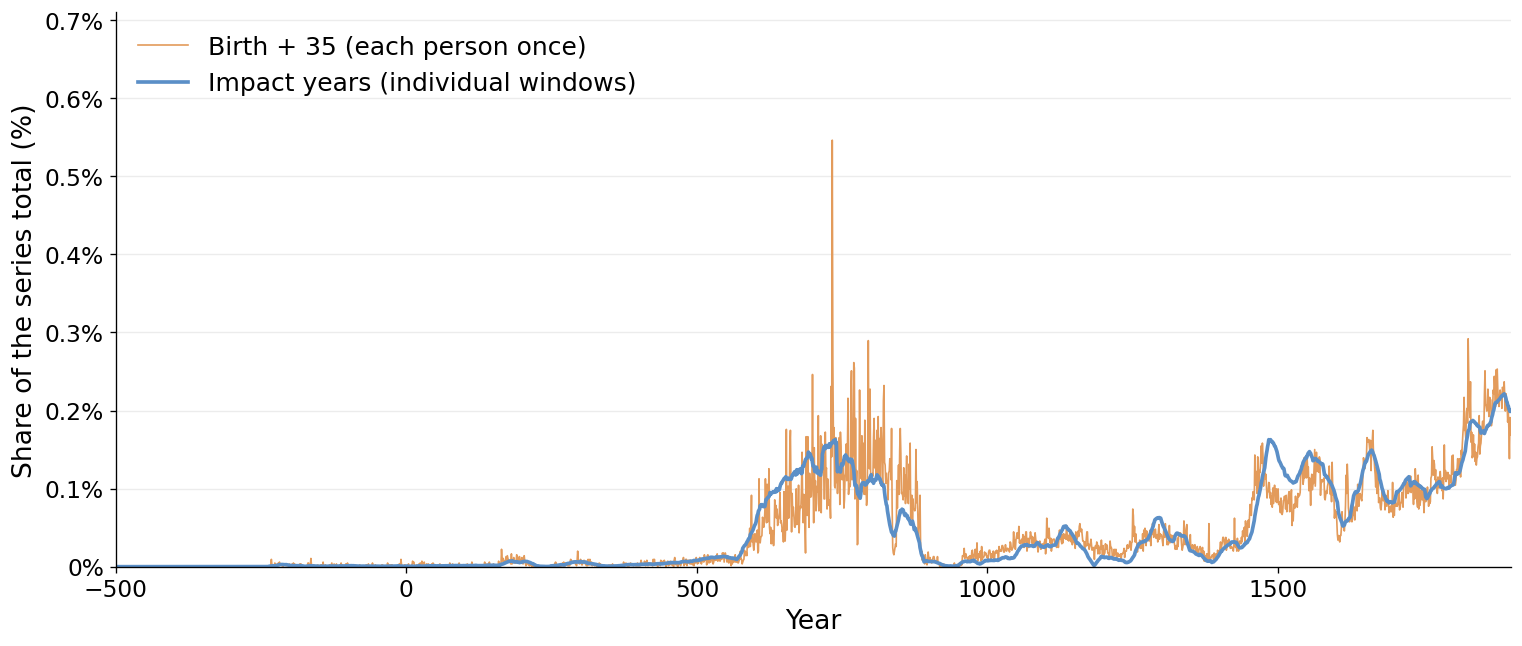

In [9]:
plot_series(yearly, ['birth_35', 'impact'], (FIRST_YEAR, LAST_YEAR))

### Figure: birth + 35 vs impact years, Ming–Qing transition

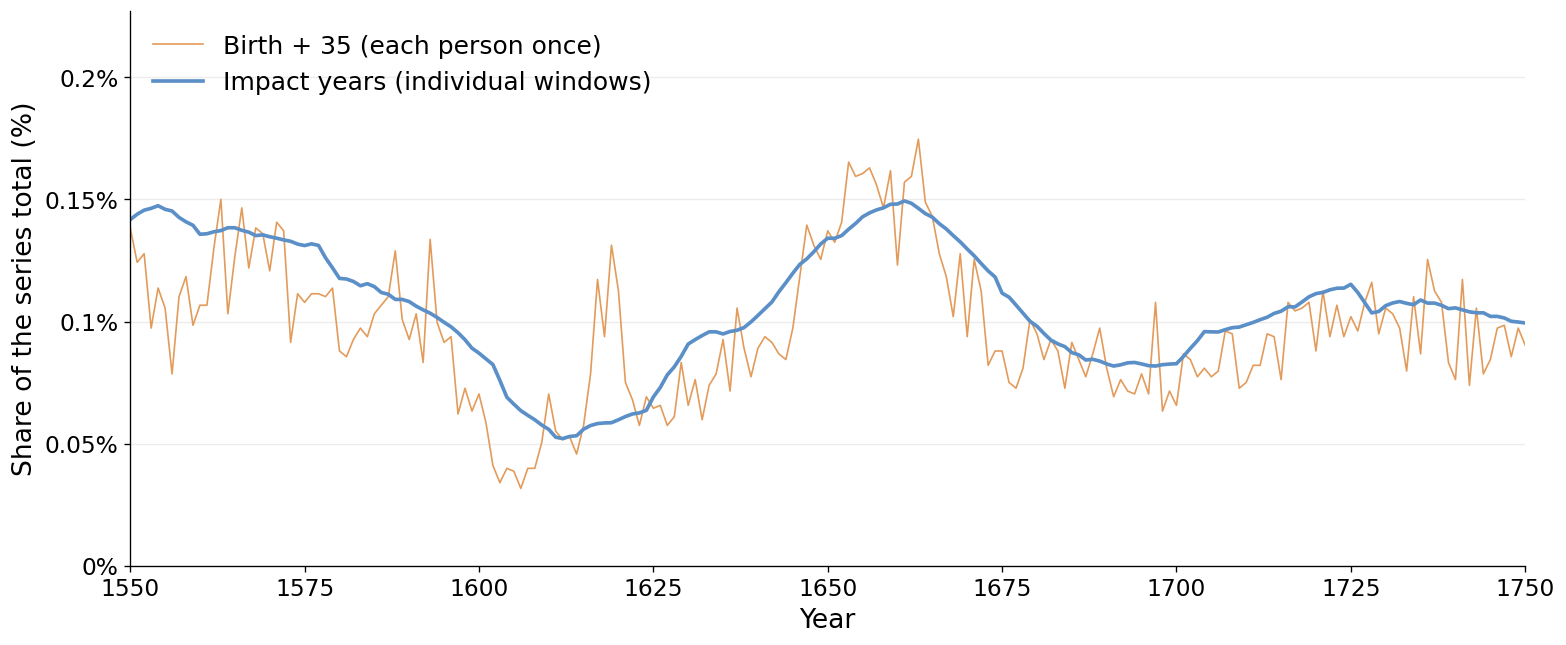

In [10]:
plot_series(zoom, ['birth_35', 'impact'], (ZOOM_FIRST, ZOOM_LAST))

### Figure: birth + 25–70 vs impact years, Chinese world
The 25–70 window is the same for everyone and ignores death; the impact window is each person's own.

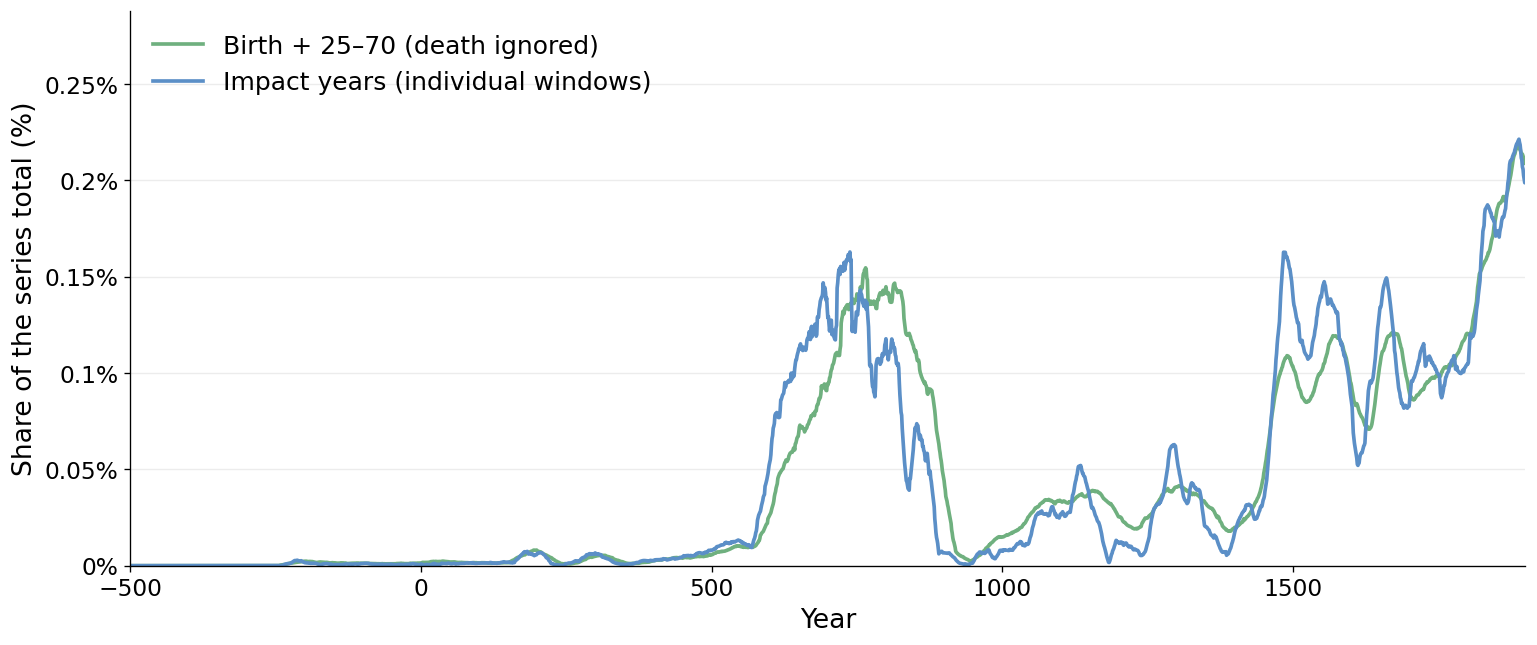

In [11]:
plot_series(yearly, ['wide_25_70', 'impact'], (FIRST_YEAR, LAST_YEAR))

### Figure: birth + 25–70 vs impact years, Ming–Qing transition

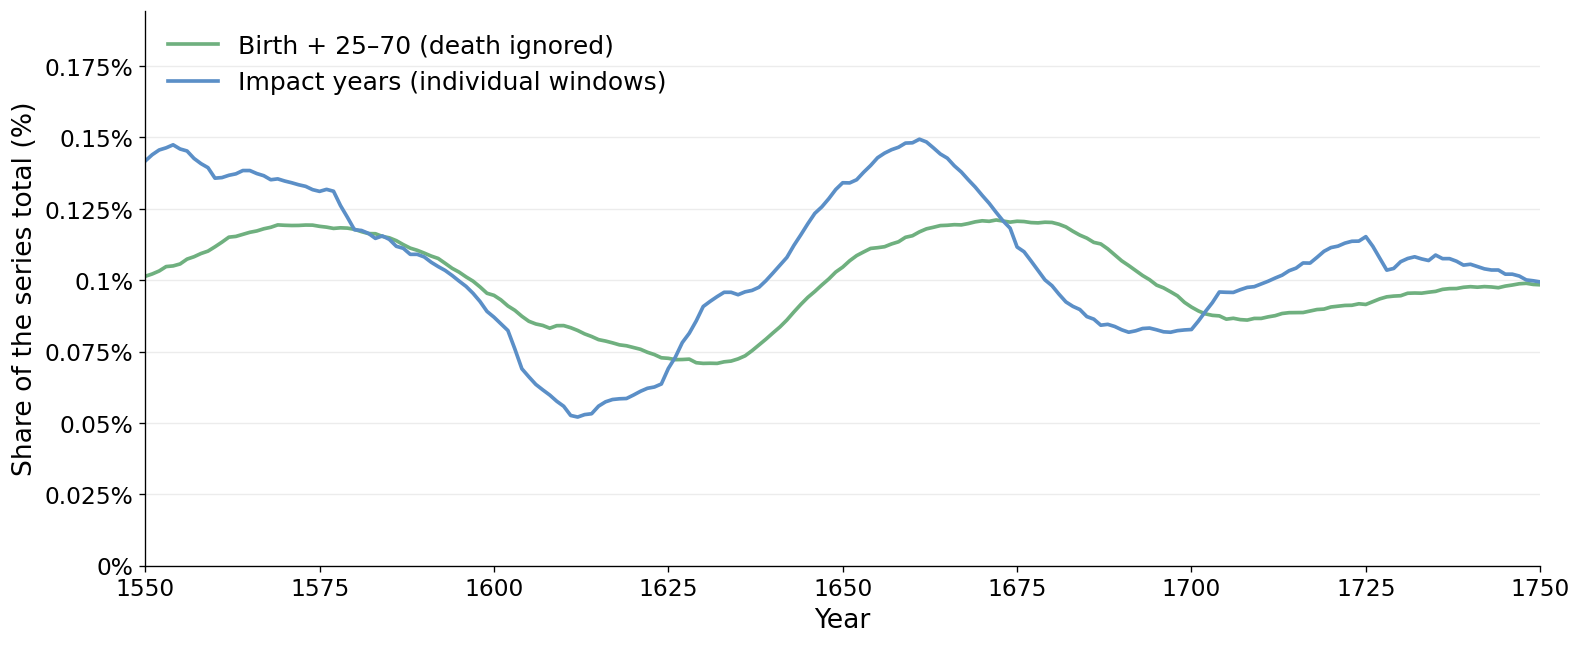

In [12]:
plot_series(zoom, ['wide_25_70', 'impact'], (ZOOM_FIRST, ZOOM_LAST))